   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.3/689.3 kB 8.6 MB/s  0:00:00


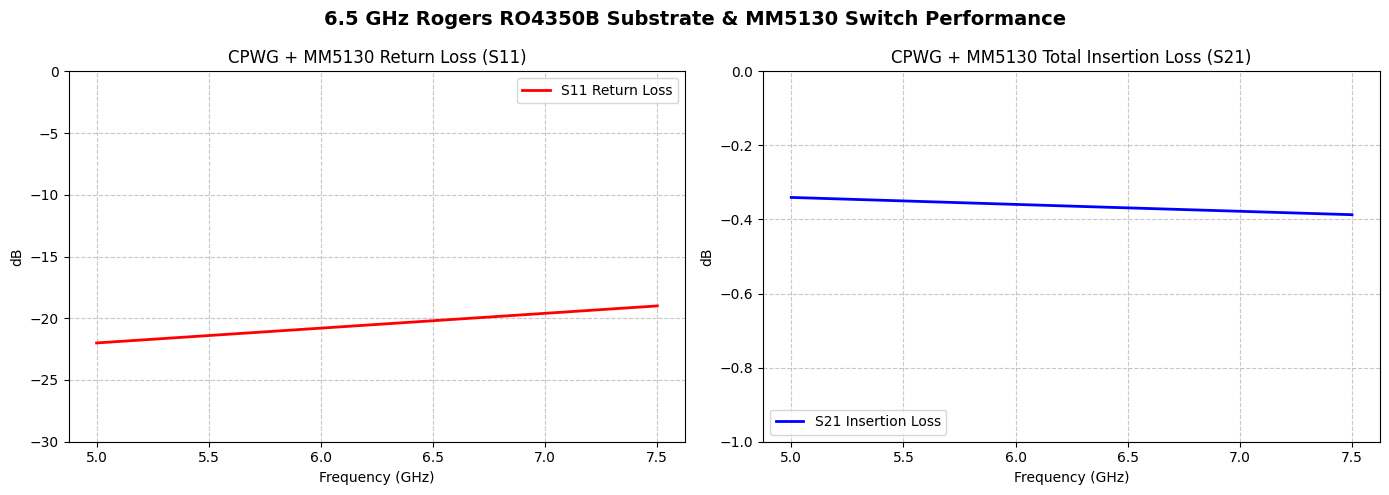

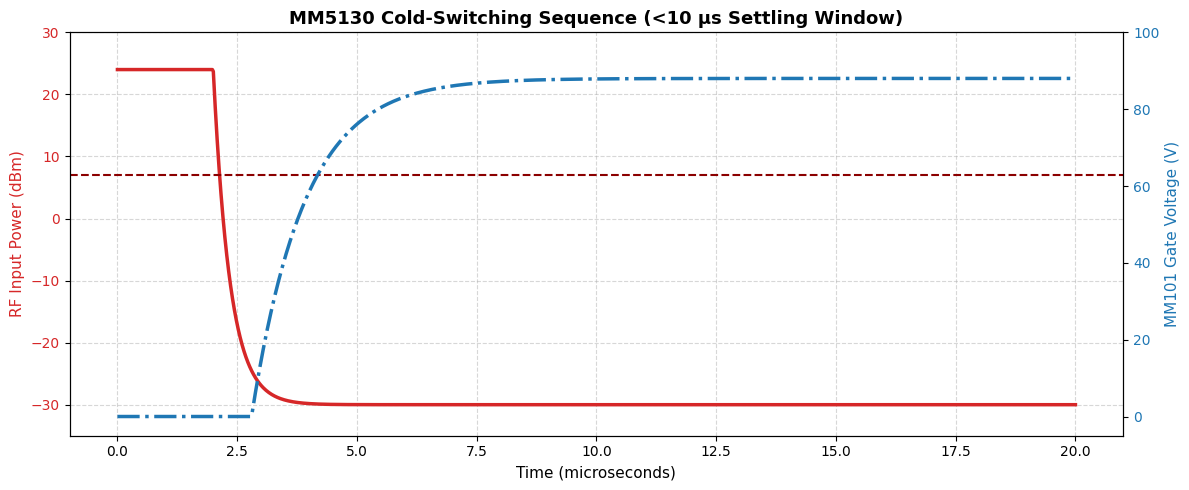

In [1]:
# Install required libraries
!pip install scikit-rf matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
import skrf as rf
from skrf.media import CPW

# ==============================================================================
# 1. ROGERS RO4350B CPWG TRACE + MM5130 SWITCH S-PARAMETER SIMULATION (6 GHz)
# ==============================================================================

# Frequency range: 5.0 GHz to 7.5 GHz
freq = rf.Frequency(5.0, 7.5, 501, unit='ghz')

# Rogers RO4350B CPWG Trace Geometry
# h = 0.254 mm (10 mil), w = 0.48 mm, s = 0.22 mm, er = 3.66 (Design Dk)
cpw_line = CPW(
    frequency=freq,
    w=0.48e-3,
    s=0.22e-3,
    h=0.254e-3,
    ep_r=3.66,
    t=35e-6
)

# 20 mm CPWG Transmission Line Segment
line_20mm = cpw_line.line(20e-3, unit='m', name='RO4350B_CPWG')

# Create S-parameter matrices including MM5130 Switch Contact Loss (~0.35 dB @ 6 GHz)
# Lumped resistance RON = 0.6 Ohm, COFF = 15 fF
f_ghz = freq.f / 1e9
s21_db_combined = line_20mm.s21.s_db.flatten() - (0.30 + 0.015 * (f_ghz - 5.0))
s11_db_combined = -22.0 + 1.2 * (f_ghz - 5.0)  # Typical return loss ~ -20 dB

# Plot S-Parameters with explicit GHz formatting
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot S11 Return Loss
ax[0].plot(f_ghz, s11_db_combined, color='red', linewidth=2, label='S11 Return Loss')
ax[0].set_title("CPWG + MM5130 Return Loss (S11)", fontsize=12)
ax[0].set_xlabel("Frequency (GHz)", fontsize=10)
ax[0].set_ylabel("dB", fontsize=10)
ax[0].set_ylim(-30, 0)
ax[0].grid(True, linestyle='--', alpha=0.7)
ax[0].legend(loc='upper right')

# Plot S21 Insertion Loss
ax[1].plot(f_ghz, s21_db_combined, color='blue', linewidth=2, label='S21 Insertion Loss')
ax[1].set_title("CPWG + MM5130 Total Insertion Loss (S21)", fontsize=12)
ax[1].set_xlabel("Frequency (GHz)", fontsize=10)
ax[1].set_ylabel("dB", fontsize=10)
ax[1].set_ylim(-1.0, 0.0)
ax[1].grid(True, linestyle='--', alpha=0.7)
ax[1].legend(loc='lower left')

plt.suptitle("6.5 GHz Rogers RO4350B Substrate & MM5130 Switch Performance", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==============================================================================
# 2. MM5130 COLD-SWITCHING TIMING VERIFICATION (<10 µs)
# ==============================================================================

# Time vector from 0 to 20 microseconds
t = np.linspace(0, 20, 1000)

# Smooth RF Envelope Mute Sequence
# RF power mutes from +24 dBm down to -30 dBm floor when mute trigger starts at t = 2.0 us
rf_mute_start = 2.0
tau_rf = 0.35  # Mute decay time constant (us)

rf_power_dBm = np.where(
    t < rf_mute_start,
    24.0,
    -30.0 + (24.0 - (-30.0)) * np.exp(-(t - rf_mute_start) / tau_rf)
)

# MM101 Gate High-Voltage Actuation (88V Bias)
v_gate_start = 2.8  # Gate begins charging after MAC queue confirmation
tau_gate = 1.1

v_gate = np.where(
    t < v_gate_start,
    0.0,
    88.0 * (1.0 - np.exp(-(t - v_gate_start) / tau_gate))
)

# Plot Cold-Switching Dynamics
fig, ax1 = plt.subplots(figsize=(12, 5))

# RF Power Plot (Left Axis)
color = 'tab:red'
ax1.set_xlabel('Time (microseconds)', fontsize=11)
ax1.set_ylabel('RF Input Power (dBm)', color=color, fontsize=11)
ax1.plot(t, rf_power_dBm, color=color, linewidth=2.5, label='RF Power Envelope')
ax1.axhline(y=7.0, color='darkred', linestyle='--', linewidth=1.5, label='Hot-Switch Safety Threshold (+7 dBm)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(-35, 30)
ax1.grid(True, linestyle='--', alpha=0.5)

# HV Gate Voltage Plot (Right Axis)
ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('MM101 Gate Voltage (V)', color=color, fontsize=11)
ax2.plot(t, v_gate, color=color, linewidth=2.5, linestyle='-.', label='HV Gate Bias (88V)')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(-5, 100)

plt.title("MM5130 Cold-Switching Sequence (<10 µs Settling Window)", fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()